In [1]:
from pathlib import Path
import struct
import gzip
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device selection
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch Version:", torch.__version__)
print("Device:", DEVICE)
print("Random Seed:", SEED)

PyTorch Version: 2.15.0+cpu
Device: cpu
Random Seed: 42


In [2]:
DATA_DIR = Path.cwd()


def find_mnist_file(filename):

    alternative_names = [
        filename,
        filename.replace("-idx", ".idx")
    ]

    for name in alternative_names:

        matches = list(DATA_DIR.rglob(name))

        matches += list(DATA_DIR.rglob(name + ".gz"))

        matches = [
            path for path in matches
            if path.is_file()
        ]

        if matches:
            return matches[0]

    raise FileNotFoundError(
        f"{filename} not found inside {DATA_DIR}"
    )


def read_mnist_images(filename):

    path = find_mnist_file(filename)

    opener = gzip.open if str(path).endswith(".gz") else open

    with opener(path, "rb") as file:

        magic, num_images, rows, cols = struct.unpack(
            ">IIII",
            file.read(16)
        )

        if magic != 2051:
            raise ValueError("Invalid MNIST image file")

        images = np.frombuffer(
            file.read(),
            dtype=np.uint8
        )

        images = images.reshape(
            num_images,
            rows,
            cols
        )

    return images


def read_mnist_labels(filename):

    path = find_mnist_file(filename)

    opener = gzip.open if str(path).endswith(".gz") else open

    with opener(path, "rb") as file:

        magic, num_labels = struct.unpack(
            ">II",
            file.read(8)
        )

        if magic != 2049:
            raise ValueError("Invalid MNIST label file")

        labels = np.frombuffer(
            file.read(),
            dtype=np.uint8
        )

    return labels


print("MNIST loading functions defined successfully.")

MNIST loading functions defined successfully.


In [3]:
# Load training images and labels
X_train_raw = read_mnist_images(
    "train-images-idx3-ubyte"
)

y_train_raw = read_mnist_labels(
    "train-labels-idx1-ubyte"
)

# Load testing images and labels
X_test_raw = read_mnist_images(
    "t10k-images-idx3-ubyte"
)

y_test_raw = read_mnist_labels(
    "t10k-labels-idx1-ubyte"
)


# Verify dataset
print("Training Images:", X_train_raw.shape)
print("Training Labels:", y_train_raw.shape)

print("Testing Images:", X_test_raw.shape)
print("Testing Labels:", y_test_raw.shape)

print("\nUnique Digit Classes:", np.unique(y_train_raw))

Training Images: (60000, 28, 28)
Training Labels: (60000,)
Testing Images: (10000, 28, 28)
Testing Labels: (10000,)

Unique Digit Classes: [0 1 2 3 4 5 6 7 8 9]


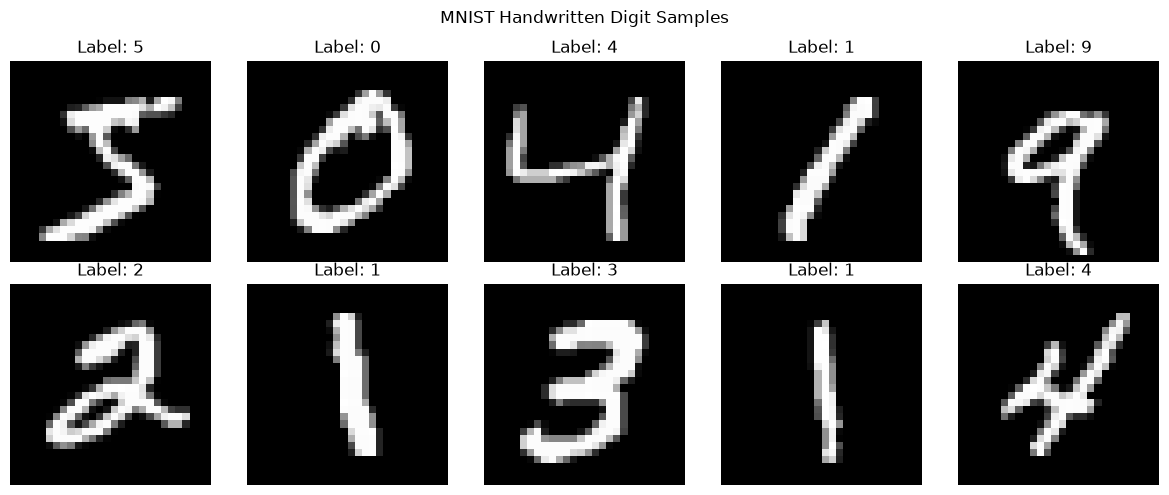

In [4]:
fig, axes = plt.subplots(
    2, 5,
    figsize=(12, 5)
)

for i, ax in enumerate(axes.flat):

    ax.imshow(
        X_train_raw[i],
        cmap="gray"
    )

    ax.set_title(
        f"Label: {y_train_raw[i]}"
    )

    ax.axis("off")


plt.suptitle(
    "MNIST Handwritten Digit Samples"
)

plt.tight_layout()
plt.show()

In [5]:
# Normalize pixel values between 0 and 1
X_train_all = X_train_raw.astype(np.float32) / 255.0

X_test = X_test_raw.astype(np.float32) / 255.0


# Flatten 28 x 28 images into 784 features
X_train_all = X_train_all.reshape(-1, 784)

X_test = X_test.reshape(-1, 784)


# Split training data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X_train_all,
    y_train_raw,
    test_size=0.10,
    random_state=SEED,
    stratify=y_train_raw
)


# Display dataset information
print("Training Shape:", X_train.shape)
print("Validation Shape:", X_val.shape)
print("Testing Shape:", X_test.shape)

print("\nMinimum Pixel Value:", X_train.min())
print("Maximum Pixel Value:", X_train.max())

print("\nTraining Labels Shape:", y_train.shape)
print("Validation Labels Shape:", y_val.shape)
print("Testing Labels Shape:", y_test_raw.shape)

Training Shape: (54000, 784)
Validation Shape: (6000, 784)
Testing Shape: (10000, 784)

Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0

Training Labels Shape: (54000,)
Validation Labels Shape: (6000,)
Testing Labels Shape: (10000,)


In [6]:
# 1. Sigmoid Activation Function
def sigmoid(x):

    x = np.clip(x, -500, 500)

    return 1 / (1 + np.exp(-x))


# Sigmoid Derivative
def sigmoid_derivative(x):

    s = sigmoid(x)

    return s * (1 - s)


# 2. ReLU Activation Function
def relu(x):

    return np.maximum(0, x)


# ReLU Derivative
def relu_derivative(x):

    return np.where(x > 0, 1, 0)


# 3. Tanh Activation Function
def tanh(x):

    return np.tanh(x)


# Tanh Derivative
def tanh_derivative(x):

    return 1 - np.tanh(x) ** 2


print("All three activation functions implemented successfully.")

print("Sigmoid, ReLU and Tanh with their derivatives are ready.")

All three activation functions implemented successfully.
Sigmoid, ReLU and Tanh with their derivatives are ready.


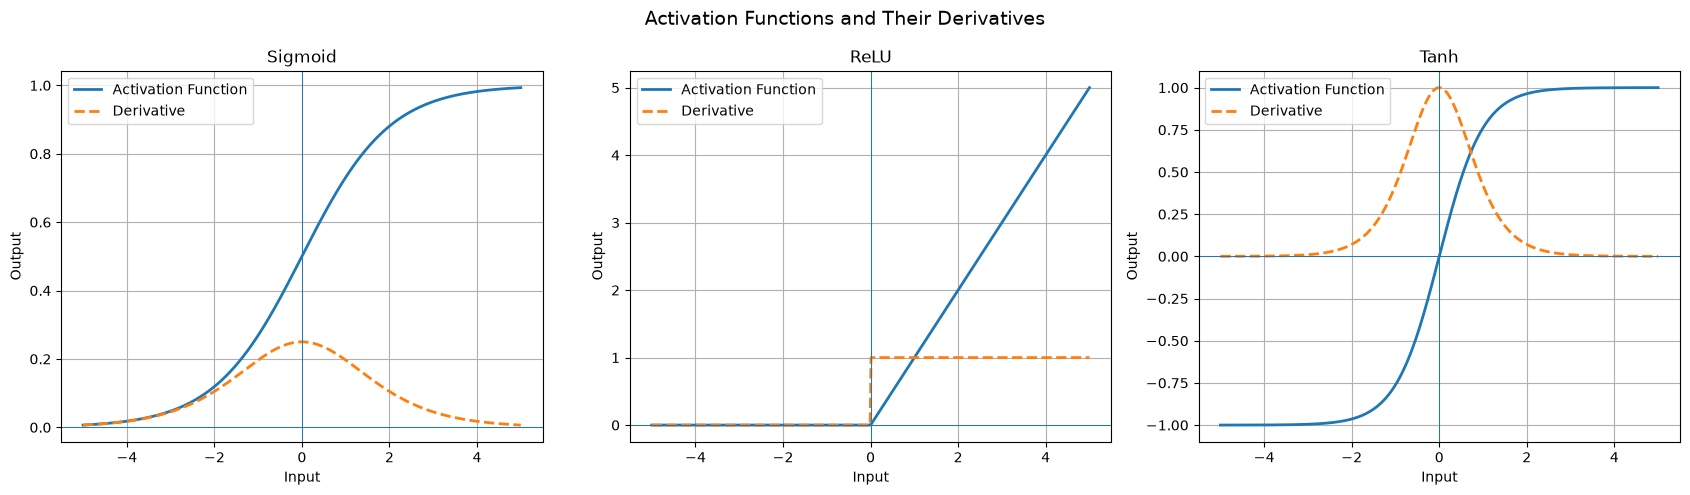

In [7]:
# Generate input values
x = np.linspace(-5, 5, 500)


# Store activation functions and derivatives
activation_functions = {

    "Sigmoid": (
        sigmoid,
        sigmoid_derivative
    ),

    "ReLU": (
        relu,
        relu_derivative
    ),

    "Tanh": (
        tanh,
        tanh_derivative
    )
}


# Create three subplots
fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5)
)


for ax, (name, functions) in zip(
    axes,
    activation_functions.items()
):

    activation, derivative = functions

    # Plot activation function
    ax.plot(
        x,
        activation(x),
        label="Activation Function",
        linewidth=2
    )

    # Plot derivative
    ax.plot(
        x,
        derivative(x),
        label="Derivative",
        linestyle="--",
        linewidth=2
    )

    ax.set_title(name)

    ax.set_xlabel("Input")

    ax.set_ylabel("Output")

    ax.axhline(0, linewidth=0.7)

    ax.axvline(0, linewidth=0.7)

    ax.legend()

    ax.grid(True)


plt.suptitle(
    "Activation Functions and Their Derivatives",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [8]:
def single_neuron(inputs, weights, bias, activation):

    # Step 1: Calculate weighted sum
    z = np.dot(inputs, weights) + bias

    # Step 2: Apply activation function
    output = activation(z)

    return z, output


# Example input values
inputs = np.array([2, 3, 4])

# Initialize weights
weights = np.array([0.5, 0.2, 0.8])

# Initialize bias
bias = 1.5


# Pass inputs through a neuron using ReLU
z, output = single_neuron(
    inputs,
    weights,
    bias,
    relu
)


# Display results
print("Input:", inputs)

print("Weights:", weights)

print("Bias:", bias)

print("Weighted Sum:", z)

print("ReLU Output:", output)

Input: [2 3 4]
Weights: [0.5 0.2 0.8]
Bias: 1.5
Weighted Sum: 6.300000000000001
ReLU Output: 6.300000000000001


In [9]:
def softmax(x):
    exp_values = np.exp(x - np.max(x, axis=1, keepdims=True))
    probabilities = exp_values / np.sum(exp_values, axis=1, keepdims=True)
    return probabilities
# 1. Select one MNIST image
image = X_train[0]

# Flatten 28x28 image into 784 values
input_layer = image.reshape(1, 784)

print("Input Layer Shape:", input_layer.shape)
print("Input Layer Values:\n", input_layer)

# 2. Initialize random weights and biases

np.random.seed(42)
 
W1 = np.random.randn(784, 64) * 0.01
b1 = np.zeros((1, 64))

W2 = np.random.randn(64, 10) * 0.01
b2 = np.zeros((1, 10))

print("\nWeight 1 Shape:", W1.shape)
print("Bias 1 Shape:", b1.shape)

print("Weight 2 Shape:", W2.shape)
print("Bias 2 Shape:", b2.shape)

# 3. Input Layer -> Hidden Layer

z1 = np.dot(input_layer, W1) + b1
hidden_layer = relu(z1)

print("\nHidden Layer")
print("Z1 Shape:", z1.shape)
print("Z1 Values:\n", z1)

print("Hidden Layer Shape:", hidden_layer.shape)
print("Hidden Layer Values:\n", hidden_layer)

# 4. Hidden Layer -> Output Layer

z2 = np.dot(hidden_layer, W2) + b2
output_layer = softmax(z2)

print("\nOutput Layer")
print("Z2 Shape:", z2.shape)
print("Z2 Values:\n", z2)

print("Output Layer Shape:", output_layer.shape)
print("Output Layer Values:\n", output_layer)

# 5. Predicted digit

predicted_digit = np.argmax(output_layer)

print("\nPredicted Digit:", predicted_digit)
print("Actual Digit:", y_train[0])

Input Layer Shape: (1, 784)
Input Layer Values:
 [[0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.   

In [10]:
# Convert NumPy arrays into PyTorch tensors

X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)

X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_raw, dtype=torch.long)

# Create TensorDatasets

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

val_dataset = TensorDataset(
    X_val_tensor,
    y_val_tensor
)

test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)


# Batch size

BATCH_SIZE = 128


# Create DataLoaders

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)


print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 422
Validation batches: 47
Testing batches: 79


In [11]:
class MNISTModel(nn.Module):

    def __init__(
        self,
        hidden_sizes=(128, 64),
        activation_name="ReLU"
    ):

        super().__init__()

        activation_options = {
            "ReLU": nn.ReLU,
            "Sigmoid": nn.Sigmoid,
            "Tanh": nn.Tanh
        }

        activation_function = activation_options[activation_name]

        layers = []

        input_size = 784

        # Create hidden layers
        for hidden_size in hidden_sizes:

            layers.append(
                nn.Linear(input_size, hidden_size)
            )

            layers.append(
                activation_function()
            )

            input_size = hidden_size

        # Output layer
        layers.append(
            nn.Linear(input_size, 10)
        )

        self.network = nn.Sequential(*layers)


    def forward(self, x):

        return self.network(x)

In [12]:
def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        # Forward propagation
        outputs = model(images)

        loss = criterion(outputs, labels)

        # Backpropagation
        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        total_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()

        total += labels.size(0)

    epoch_loss = total_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


def evaluate_model(model, loader, criterion):

    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)

            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()

            total += labels.size(0)

    average_loss = total_loss / total
    accuracy = correct / total

    return average_loss, accuracy

In [13]:
# Initialize model

model = MNISTModel(
    hidden_sizes=(128, 64),
    activation_name="ReLU"
).to(DEVICE)


# Loss function and optimizer

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)


# Store accuracy and loss

train_accuracies = []
val_accuracies = []

train_losses = []
val_losses = []


# Train for 15 epochs

EPOCHS = 15

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    val_loss, val_acc = evaluate_model(
        model,
        val_loader,
        criterion
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"Train Accuracy: {train_acc:.4f} "
        f"Validation Accuracy: {val_acc:.4f}"
    )

Epoch [1/15] Train Accuracy: 0.8830 Validation Accuracy: 0.9263
Epoch [2/15] Train Accuracy: 0.9453 Validation Accuracy: 0.9498
Epoch [3/15] Train Accuracy: 0.9602 Validation Accuracy: 0.9587
Epoch [4/15] Train Accuracy: 0.9698 Validation Accuracy: 0.9628
Epoch [5/15] Train Accuracy: 0.9755 Validation Accuracy: 0.9652
Epoch [6/15] Train Accuracy: 0.9794 Validation Accuracy: 0.9698
Epoch [7/15] Train Accuracy: 0.9832 Validation Accuracy: 0.9672
Epoch [8/15] Train Accuracy: 0.9859 Validation Accuracy: 0.9740
Epoch [9/15] Train Accuracy: 0.9885 Validation Accuracy: 0.9757
Epoch [10/15] Train Accuracy: 0.9909 Validation Accuracy: 0.9715
Epoch [11/15] Train Accuracy: 0.9927 Validation Accuracy: 0.9753
Epoch [12/15] Train Accuracy: 0.9940 Validation Accuracy: 0.9732
Epoch [13/15] Train Accuracy: 0.9943 Validation Accuracy: 0.9735
Epoch [14/15] Train Accuracy: 0.9958 Validation Accuracy: 0.9747
Epoch [15/15] Train Accuracy: 0.9959 Validation Accuracy: 0.9740


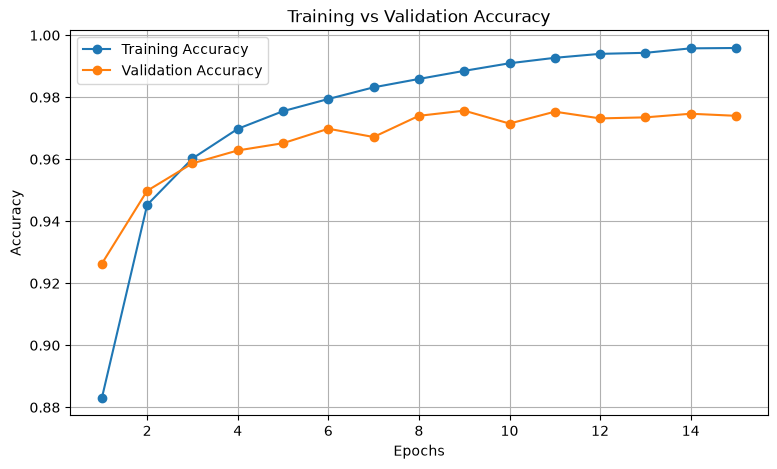

In [14]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, EPOCHS + 1),
    train_accuracies,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    range(1, EPOCHS + 1),
    val_accuracies,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.title("Training vs Validation Accuracy")

plt.legend()
plt.grid(True)

plt.show()

In [15]:
test_loss, test_accuracy = evaluate_model(
    model,
    test_loader,
    criterion
)

print("Test Loss:", round(test_loss, 4))

print(
    "Test Accuracy:",
    round(test_accuracy * 100, 2), 
    "%"
)

Test Loss: 0.0952
Test Accuracy: 97.58 %


In [16]:
def run_experiment(
    hidden_sizes,
    learning_rate,
    epochs=5,
    activation_name="ReLU"
):

    experiment_model = MNISTModel(
        hidden_sizes=hidden_sizes,
        activation_name=activation_name
    ).to(DEVICE)

    experiment_criterion = nn.CrossEntropyLoss()

    experiment_optimizer = optim.Adam(
        experiment_model.parameters(),
        lr=learning_rate
    )

    for epoch in range(epochs):

        train_one_epoch(
            experiment_model,
            train_loader,
            experiment_criterion,
            experiment_optimizer
        )

    _, final_val_accuracy = evaluate_model(
        experiment_model,
        val_loader,
        experiment_criterion
    )

    _, final_test_accuracy = evaluate_model(
        experiment_model,
        test_loader,
        experiment_criterion
    )

    return final_val_accuracy, final_test_accuracy

In [17]:
learning_rates = [0.001, 0.01, 0.1]

learning_rate_results = []

for lr in learning_rates:

    val_acc, test_acc = run_experiment(
        hidden_sizes=(128, 64),
        learning_rate=lr,
        epochs=5
    )

    learning_rate_results.append({
        "Experiment": "Learning Rate",
        "Configuration": str(lr),
        "Validation Accuracy": val_acc,
        "Test Accuracy": test_acc
    })

    print(
        f"Learning Rate: {lr} | "
        f"Validation Accuracy: {val_acc:.4f} | "
        f"Test Accuracy: {test_acc:.4f}"
    )

Learning Rate: 0.001 | Validation Accuracy: 0.9698 | Test Accuracy: 0.9724
Learning Rate: 0.01 | Validation Accuracy: 0.9672 | Test Accuracy: 0.9725
Learning Rate: 0.1 | Validation Accuracy: 0.5805 | Test Accuracy: 0.5888


In [18]:
hidden_sizes_list = [32, 64, 128, 256]

hidden_size_results = []

for size in hidden_sizes_list:

    val_acc, test_acc = run_experiment(
        hidden_sizes=(size,),
        learning_rate=0.001,
        epochs=5
    )

    hidden_size_results.append({
        "Experiment": "Hidden Layer Size",
        "Configuration": str(size),
        "Validation Accuracy": val_acc,
        "Test Accuracy": test_acc
    })

    print(
        f"Hidden Neurons: {size} | "
        f"Validation Accuracy: {val_acc:.4f} | "
        f"Test Accuracy: {test_acc:.4f}"
    )

Hidden Neurons: 32 | Validation Accuracy: 0.9477 | Test Accuracy: 0.9490
Hidden Neurons: 64 | Validation Accuracy: 0.9552 | Test Accuracy: 0.9606
Hidden Neurons: 128 | Validation Accuracy: 0.9645 | Test Accuracy: 0.9678
Hidden Neurons: 256 | Validation Accuracy: 0.9725 | Test Accuracy: 0.9745


In [19]:
layer_configurations = {
    "1 Hidden Layer": (128,),
    "2 Hidden Layers": (128, 64),
    "3 Hidden Layers": (128, 64, 32)
}

layer_results = []

for name, sizes in layer_configurations.items():

    val_acc, test_acc = run_experiment(
        hidden_sizes=sizes,
        learning_rate=0.001,
        epochs=5
    )

    layer_results.append({
        "Experiment": "Number of Hidden Layers",
        "Configuration": name,
        "Validation Accuracy": val_acc,
        "Test Accuracy": test_acc
    })

    print(
        f"{name} | "
        f"Validation Accuracy: {val_acc:.4f} | "
        f"Test Accuracy: {test_acc:.4f}"
    )

1 Hidden Layer | Validation Accuracy: 0.9645 | Test Accuracy: 0.9685
2 Hidden Layers | Validation Accuracy: 0.9668 | Test Accuracy: 0.9692
3 Hidden Layers | Validation Accuracy: 0.9643 | Test Accuracy: 0.9665


In [20]:
all_results = (
    learning_rate_results
    + hidden_size_results
    + layer_results
)

experiment_df = pd.DataFrame(all_results)

experiment_df["Validation Accuracy"] = (
    experiment_df["Validation Accuracy"] * 100
)

experiment_df["Test Accuracy"] = (
    experiment_df["Test Accuracy"] * 100
)

experiment_df = experiment_df.round(2)

display(experiment_df)

,Experiment,Configuration,Validation Accuracy,Test Accuracy
0,Learning Rate,0.001,96.98,97.24
1,Learning Rate,0.01,96.72,97.25
2,Learning Rate,0.1,58.05,58.88
3,Hidden Layer Size,32,94.77,94.90
4,Hidden Layer Size,64,95.52,96.06
5,Hidden Layer Size,128,96.45,96.78
6,Hidden Layer Size,256,97.25,97.45
7,Number of Hidden Layers,1 Hidden Layer,96.45,96.85
8,Number of Hidden Layers,2 Hidden Layers,96.68,96.92
9,Number of Hidden Layers,3 Hidden Layers,96.43,96.65


In [21]:
best_experiment = experiment_df.loc[
    experiment_df["Test Accuracy"].idxmax()
]

print("Best Experiment:")
print(best_experiment) 

Best Experiment:
Experiment             Hidden Layer Size
Configuration                        256
Validation Accuracy                97.25
Test Accuracy                      97.45
Name: 6, dtype: object


In [22]:
import time

activation_names = [
    "Sigmoid",
    "ReLU",
    "Tanh"
]

activation_results = []

activation_histories = {}

ACTIVATION_EPOCHS = 15

for activation_name in activation_names:

    print(f"\nTraining with {activation_name}")

    activation_model = MNISTModel(
        hidden_sizes=(128, 64),
        activation_name=activation_name
    ).to(DEVICE)

    activation_criterion = nn.CrossEntropyLoss()

    activation_optimizer = optim.Adam(
        activation_model.parameters(),
        lr=0.001
    )

    start_time = time.time()

    time_to_90 = None

    train_history = []

    for epoch in range(ACTIVATION_EPOCHS):

        _, train_acc = train_one_epoch(
            activation_model,
            train_loader,
            activation_criterion,
            activation_optimizer
        )

        train_history.append(train_acc)

        elapsed_time = time.time() - start_time

        # Record the first epoch where training accuracy reaches 90%
        if train_acc >= 0.90 and time_to_90 is None:

            time_to_90 = elapsed_time

        print(
            f"Epoch {epoch + 1}/{ACTIVATION_EPOCHS} "
            f"Training Accuracy: {train_acc:.4f}"
        )

    total_training_time = time.time() - start_time

    _, final_test_acc = evaluate_model(
        activation_model,
        test_loader,
        activation_criterion
    )

    activation_histories[activation_name] = train_history

    activation_results.append({
        "Activation": activation_name,
        "Time to 90% Training Accuracy (seconds)": (
            round(time_to_90, 2)
            if time_to_90 is not None
            else "Not reached"
        ),
        "Total Training Time (seconds)": round(
            total_training_time, 2
        ),
        "Final Test Accuracy (%)": round(
            final_test_acc * 100, 2
        )
    })


activation_df = pd.DataFrame(activation_results)

display(activation_df)


Training with Sigmoid
Epoch 1/15 Training Accuracy: 0.7444
Epoch 2/15 Training Accuracy: 0.9184
Epoch 3/15 Training Accuracy: 0.9386
Epoch 4/15 Training Accuracy: 0.9507
Epoch 5/15 Training Accuracy: 0.9595
Epoch 6/15 Training Accuracy: 0.9660
Epoch 7/15 Training Accuracy: 0.9719
Epoch 8/15 Training Accuracy: 0.9754
Epoch 9/15 Training Accuracy: 0.9792
Epoch 10/15 Training Accuracy: 0.9820
Epoch 11/15 Training Accuracy: 0.9839
Epoch 12/15 Training Accuracy: 0.9865
Epoch 13/15 Training Accuracy: 0.9885
Epoch 14/15 Training Accuracy: 0.9905
Epoch 15/15 Training Accuracy: 0.9918

Training with ReLU
Epoch 1/15 Training Accuracy: 0.8781
Epoch 2/15 Training Accuracy: 0.9439
Epoch 3/15 Training Accuracy: 0.9612
Epoch 4/15 Training Accuracy: 0.9693
Epoch 5/15 Training Accuracy: 0.9749
Epoch 6/15 Training Accuracy: 0.9809
Epoch 7/15 Training Accuracy: 0.9835
Epoch 8/15 Training Accuracy: 0.9864
Epoch 9/15 Training Accuracy: 0.9888
Epoch 10/15 Training Accuracy: 0.9907
Epoch 11/15 Training Accu

,Activation,Time to 90% Training Accuracy (seconds),Total Training Time (seconds),Final Test Accuracy (%)
0,Sigmoid,3.88,28.10,97.59
1,ReLU,4.38,28.54,97.76
2,Tanh,3.33,24.69,97.65


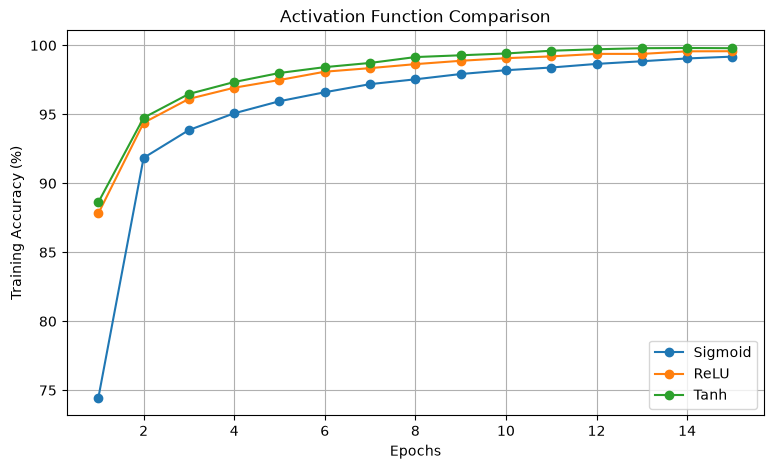

In [23]:
plt.figure(figsize=(9, 5))

for activation_name, history in activation_histories.items():

    plt.plot(
        range(1, ACTIVATION_EPOCHS + 1),
        np.array(history) * 100,
        marker="o",
        label=activation_name
    )

plt.xlabel("Epochs")
plt.ylabel("Training Accuracy (%)")

plt.title("Activation Function Comparison")

plt.legend()
plt.grid(True)

plt.show()

In [24]:
model.eval()

all_predictions = []
all_actual_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(DEVICE)

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_actual_labels.extend(
            labels.numpy()
        )


all_predictions = np.array(all_predictions)
all_actual_labels = np.array(all_actual_labels)


print("Predictions Shape:", all_predictions.shape)
print("Actual Labels Shape:", all_actual_labels.shape)

print(
    "Test Accuracy:",
    round(
        accuracy_score(
            all_actual_labels,
            all_predictions
        ) * 100,
        2
    ),
    "%"
)

Predictions Shape: (10000,)
Actual Labels Shape: (10000,)
Test Accuracy: 97.58 %


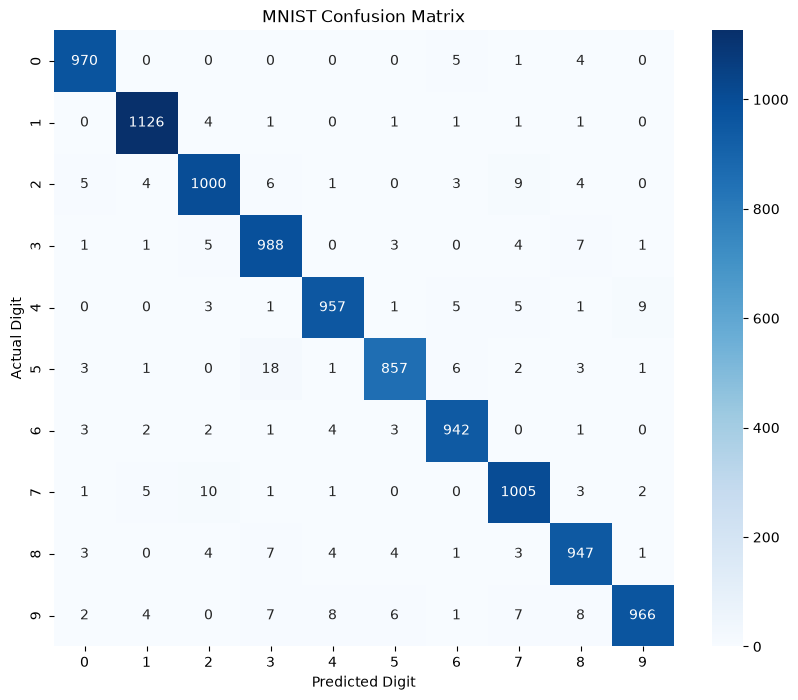

In [25]:
cm = confusion_matrix(
    all_actual_labels,
    all_predictions
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")

plt.title("MNIST Confusion Matrix")

plt.show()

In [26]:
confused_pairs = []

for actual_digit in range(10):

    for predicted_digit in range(actual_digit + 1, 10):

        confusion_count = (
            cm[actual_digit, predicted_digit]
            +
            cm[predicted_digit, actual_digit]
        )

        confused_pairs.append({
            "Digit Pair": f"{actual_digit} and {predicted_digit}",
            "Confusion Count": confusion_count
        })


confused_pairs_df = pd.DataFrame(confused_pairs)

confused_pairs_df = confused_pairs_df.sort_values(
    by="Confusion Count",
    ascending=False
)

print("Top 3 Most Confused Digit Pairs:")

display(
    confused_pairs_df.head(3)
)

Top 3 Most Confused Digit Pairs:


,Digit Pair,Confusion Count
25,3 and 5,21
21,2 and 7,19
34,4 and 9,17


Total Misclassified Images: 242


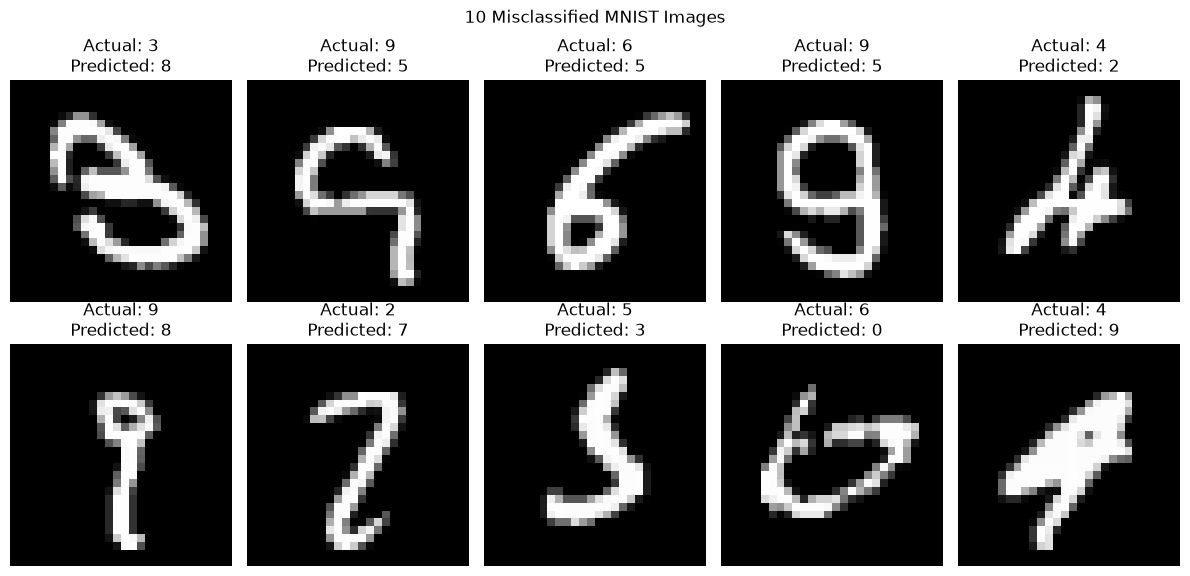

In [ ]:
misclassified_indices = np.where(
    all_predictions != all_actual_labels
)[0]

print(
    "Total Misclassified Images:",
    len(misclassified_indices)
)

# Select first 10 misclassified examples
selected_indices = misclassified_indices[:10]

fig, axes = plt.subplots(
    2, 5,
    figsize=(12, 6)
)

for ax, index in zip(
    axes.flat,
    selected_indices
):

    image = X_test_raw[index]

    actual = all_actual_labels[index]

    predicted = all_predictions[index]

    ax.imshow(
        image,
        cmap="gray"
    )

    ax.set_title(
        f"Actual: {actual}\nPredicted: {predicted}"
    )

    ax.axis("off")


plt.suptitle("10 Misclassified MNIST Images")

plt.tight_layout()
plt.show()

In [28]:
per_digit_results = []

for digit in range(10):

    total_images = np.sum(
        all_actual_labels == digit
    )

    correct_predictions = np.sum(
        (all_actual_labels == digit)
        &
        (all_predictions == digit)
    )

    digit_accuracy = (
        correct_predictions / total_images
    ) * 100

    per_digit_results.append({
        "Digit": digit,
        "Total Images": total_images,
        "Correct Predictions": correct_predictions,
        "Accuracy (%)": round(digit_accuracy, 2)
    })


per_digit_df = pd.DataFrame(
    per_digit_results
)

display(per_digit_df)

,Digit,Total Images,Correct Predictions,Accuracy (%)
0,0,980,970,98.98
1,1,1135,1126,99.21
2,2,1032,1000,96.90
3,3,1010,988,97.82
4,4,982,957,97.45
5,5,892,857,96.08
6,6,958,942,98.33
7,7,1028,1005,97.76
8,8,974,947,97.23
9,9,1009,966,95.74


In [29]:
easiest_digit = per_digit_df.loc[
    per_digit_df["Accuracy (%)"].idxmax()
]

hardest_digit = per_digit_df.loc[
    per_digit_df["Accuracy (%)"].idxmin()
]

print("Easiest Digit:")
print(easiest_digit)

print("\nHardest Digit:")
print(hardest_digit)

Easiest Digit:
Digit                     1.00
Total Images           1135.00
Correct Predictions    1126.00
Accuracy (%)             99.21
Name: 1, dtype: float64

Hardest Digit:
Digit                     9.00
Total Images           1009.00
Correct Predictions     966.00
Accuracy (%)             95.74
Name: 9, dtype: float64
